In [4]:
from base64 import b64encode
from itertools import product
from pathlib import Path
import json

import imageio_ffmpeg
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.colors import LogNorm

from shared.common import load_config, plot_setup

In [5]:
pip install imageio_ffmpeg


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
settings = load_config()
config = settings['coast']
inp, out = Path('../input'), Path('../output')
dx, dy, dz = config['spacing_m']
nx, ny, nz = config['shape']
region_names = ['Mountain', 'Rural', 'Suburban', 'City', 'Ocean']
region_colors = ['#8B826B', '#80A572', '#C8AE79', '#B5AC9F', '#6AAAC0']
source_names = ['Windward CO₂', 'Rural CO₂', 'Suburban CO₂ and VOC', 'City CO₂, VOC, and aerosol']
plot_setup()

[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [7]:
with np.load(inp / 'demo_frames.npz') as saved:
    frames = {key: saved[key] for key in saved.files}
ledger = pd.read_csv(inp / 'demo_ledger.csv')
concentrations = frames['air_kg_c']*1e6/(dx*dy*dz)
land = frames['terrain_cells']*dz
zones = frames['zone']
ground = np.where(zones == 3, 0, land)
x = (np.arange(nx)+0.5)*dx/1000
y = (np.arange(ny)+0.5)*dy/1000
z = (np.arange(nz)+0.5)*dz
river_i, river_j = frames['river_x'], frames['river_y']
src_i, src_j, src_k = frames['source_indices'].T

In [8]:
# sample visible cells once per frame on a fixed species-specific color scale
rng = np.random.default_rng(settings['seed'])
priority = rng.random(nx*ny*nz)
assert nx*ny*nz <= 65536
vis_min, vis_max = [], []
for s in range(len(frames['species'])):
    species = concentrations[..., s]
    vmax = np.quantile(species[species > 0], 0.996)
    vis_min.append(float(vmax/100))
    vis_max.append(float(vmax))

def cloud(scenario, frame, species):
    field = concentrations[scenario, frame, ..., species].ravel()
    ids = np.flatnonzero(field >= vis_min[species])
    if len(ids) > 150:
        strongest = ids[np.argsort(field[ids], kind='stable')[-35:]]
        rest = np.setdiff1d(ids, strongest)
        ids = np.r_[rest[np.argsort(priority[rest])[:115]], strongest]
    return ids, field[ids]

def encode_cloud(ids, values, species):
    span = np.log10(vis_max[species]/vis_min[species])
    color = np.clip(np.rint(255*np.log10(values/vis_min[species])/span), 0, 255).astype(np.uint8)
    return b64encode(np.column_stack([ids % 256, ids // 256, color]).astype(np.uint8).tobytes()).decode('ascii')

In [9]:
# stepped terrain + building volumes
blocks = np.argwhere((zones == 3) & (land > 0))
vertices, triangles = [], []
cube = list(product([0, 1], repeat=3))
faces = [(0, 4, 6, 2), (1, 3, 7, 5), (0, 1, 5, 4),
         (2, 6, 7, 3), (0, 2, 3, 1), (4, 5, 7, 6)]
for i, j in blocks:
    start = len(vertices)
    vertices.extend([((i+a)*dx/1000, (j+b)*dy/1000, c*land[i, j]) for a, b, c in cube])
    for a, b, c, d in faces:
        triangles.extend([(start+a, start+b, start+c), (start+a, start+c, start+d)])
mesh = dict(zip('xyz', np.asarray(vertices, dtype=float).T.tolist()))
mesh.update(dict(zip('ijk', np.asarray(triangles, dtype=int).T.tolist())))

In [10]:
time_s = frames['time_s'].tolist()
scenarios = frames['scenario'].tolist()
species = frames['species'].tolist()
codes = [[[encode_cloud(*cloud(s, t, k), k) for k in range(len(species))]
          for t in range(len(time_s))] for s in range(len(scenarios))]
stats = []
for scenario in scenarios:
    rows = ledger.loc[ledger['scenario'].eq(scenario)].set_index('time_s').reindex(time_s).fillna(0)
    stats.append(np.round(np.column_stack([
        rows[['air_co2_kg_c', 'air_voc_kg_c', 'air_aerosol_kg_c']].sum(axis=1),
        rows['land_kg_c'], rows['ocean_kg_c'], rows['marine_sediment_kg_c'],
    ]), 2).tolist())
data = dict(x=x.tolist(), y=y.tolist(), z=z.tolist(), ground=ground.T.tolist(), zone=zones.T.tolist(),
            colors=region_colors, regions=region_names, mesh=mesh, scenarios=scenarios, species=species,
            time_s=time_s, shapes=[nx, ny, nz], cloud=codes, min=vis_min, max=vis_max, stats=stats,
            river=[x[river_i].tolist(), y[river_j].tolist(), (land[river_i, river_j]+3).tolist()],
            sediment=np.round(frames['river_kg_c'], 3).tolist(),
            sources=[x[src_i].tolist(), y[src_j].tolist(), z[src_k].tolist(),
                     z[src_k-frames['terrain_cells'][src_i, src_j]].tolist(), source_names])

In [11]:
page = """<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Carbon across the coast</title>
<style>
:root{font:16px system-ui,sans-serif;color:#202d38;background:#f1f4f5;color-scheme:light}
body{margin:0} main{max-width:1240px;margin:auto;padding:28px 24px}
h1{font-size:clamp(1.8rem,4vw,2.8rem);line-height:1.1;margin:6px 0 10px}
p{max-width:78ch;margin:7px 0 14px;line-height:1.45}
.kicker{font-size:.78rem;letter-spacing:.14em;color:#356674;font-weight:750}
.controls,.stats,.terrain{display:flex;flex-wrap:wrap;align-items:end;gap:12px 22px}
label{display:grid;gap:5px;font-size:.86rem;font-weight:650}
select,button{font:inherit;color:inherit;border:1px solid #748994;border-radius:5px;padding:6px 9px;background:#fff}
button{cursor:pointer;background:#164c5e;color:#fff;border-color:#164c5e}
.time{flex:1;min-width:220px}.time input{width:100%;accent-color:#164c5e;margin:0}
#view{display:block;width:100%;height:clamp(385px,63vh,610px);margin:14px 0 8px;background:#fff;border-radius:10px;touch-action:none;cursor:grab}
#view:active{cursor:grabbing}.scale{min-width:150px;display:inline-grid;gap:4px}
.scale i{height:8px;border-radius:3px;background:linear-gradient(90deg,#440154,#3b528b,#21918c,#5ec962,#fde725)}
#inspect{color:#42545e;min-height:1.2em;font-size:.86rem}
#reset{background:#fff;color:#164c5e}
.stats{align-items:stretch}.card{padding:9px 13px;border-radius:7px;background:#fff;min-width:128px}
.card b{display:block;font-size:1.3rem}.card span{font-size:.84rem}
.terrain{gap:6px 15px;margin:9px 0 12px;font-size:.86rem}
.swatch{display:inline-block;width:.7rem;height:.7rem;border-radius:2px;margin-right:5px}
.note{font-size:.84rem;color:#42545e} :focus-visible{outline:3px solid #b44a2b;outline-offset:2px}
</style>
</head>
<body><main>
<div class="kicker">COASTAL CARBON · LATTICE SIMULATION</div>
<h1>Carbon across the coast</h1>
<p>Follow an urban plume and carbonate runoff across a 6.4 km transect. Change the forcing and drag the scene to inspect the ridge, city blocks, and shoreline.</p>
<div class="controls">
<label>Scenario<select id="scenario"></select></label>
<label>Airborne carbon<select id="species"></select></label>
<label class="time">Simulated time <output id="minutes"></output><input type="range" id="time" min="0" value="6" step="1" aria-label="Simulation frame"></label>
<button id="play" type="button">Play</button>
<button id="reset" type="button">Reset view</button>
</div>
<canvas id="view" tabindex="0" aria-label="3D coast. Drag or use arrow keys to rotate. Scroll to zoom."></canvas>
<div class="terrain"><div id="terrain" class="terrain"></div><span class="scale"><i></i><span id="scale"></span></span></div>
<div id="inspect">Drag to rotate · Scroll to zoom · Point at a source or concentration cell to inspect it</div>
<div class="stats" id="stats"></div>
<p class="note">Cloud markers are sampled grid cells colored by modeled concentration on a fixed logarithmic scale for each carbon form. The white diamonds mark emission patches. The blue line marks the river, with dots sized by carbonate in each cell. The vertical axis is exaggerated.</p>
</main>
<script>
const d = __DATA__;
const $ = id => document.getElementById(id);
for (const [id, values] of [['scenario', d.scenarios], ['species', d.species]]) {
  values.forEach((name, i) => $(id).add(new Option(name, i)));
}
$('species').value = '2';
$('time').max = d.time_s.length - 1;
$('terrain').innerHTML = d.regions.map((name, i) =>
  '<span><i class="swatch" style="background:'+d.colors[i]+'"></i>'+name+'</span>').join('');

const canvas=$('view'), ctx=canvas.getContext('2d');
const [nx,ny,nz]=d.shapes, cx=(d.x[0]+d.x[nx-1])/2, cy=(d.y[0]+d.y[ny-1])/2;
const cam={az:.43,el:.49,zoom:1};
const gradient=[[68,1,84],[59,82,139],[33,145,140],[94,201,98],[253,231,37]];
function rgba(value){
  const v=Math.max(0,Math.min(255,value))*4/255, a=Math.min(3,Math.floor(v));
  return 'rgba('+gradient[a].map((c,i)=>Math.round(c+(gradient[a+1][i]-c)*(v-a))).join(',')+',.85)';
}
const blocks=d.mesh.i.map((i,k)=>[i,d.mesh.j[k],d.mesh.k[k]].map(j=>[d.mesh.x[j],d.mesh.y[j],d.mesh.z[j]]));
let viewW,viewH,targets=[], drag, queued=false;
function requestDraw(){
  if(!queued){queued=true;requestAnimationFrame(()=>{queued=false;draw();});}
}
function draw(){
  const s=+$('scenario').value,k=+$('species').value,t=+$('time').value;
  const flat=d.scenarios[s]==='Flat terrain';
  const a=Math.cos(cam.az),b=Math.sin(cam.az),e=Math.sin(cam.el),f=Math.cos(cam.el);
  const scale=Math.min(viewW/(2*cx+cy+1),viewH/(cy+2.1))*cam.zoom;
  function project([x,y,z]){
    x-=cx; y-=cy; z*=.0035;
    const right=a*x-b*y, far=b*x+a*y;
    return [viewW*.50+scale*right,viewH*.61-scale*(e*far+f*z),e*z-f*far];
  }
  const shapes=[];
  function add(kind, points, color, size=0, info=''){
    const p=points.map(project), depth=p.reduce((sum,v)=>sum+v[2],0)/p.length;
    shapes.push({kind,p,color,size,info,depth});
  }
  for(let j=0;j<ny-1;j++){
    for(let i=0;i<nx-1;i++){
      const q=[[i,j],[i+1,j],[i+1,j+1],[i,j+1]];
      add('face',q.map(([x,y])=>[d.x[x],d.y[y],flat?0:d.ground[y][x]]),d.colors[d.zone[j][i]]);
    }
  }
  if(!flat) blocks.forEach((points,i)=>add('face',points,i%3?'#746E81':'#A9A4B0'));
  for(let i=0;i<d.river[0].length;i++){
    const point=j=>[d.river[0][j],d.river[1][j],flat?5:d.river[2][j]+3];
    if(i) add('line',[point(i-1),point(i)],'#14628C',2.5);
    const v=d.sediment[s][t][i];
    if(v>.005) add('point',[point(i)],'#86DBF1',1.5+2*Math.sqrt(v),'River cell · '+v.toFixed(2)+' kg carbonate C');
  }
  for(let i=0;i<d.sources[0].length;i++){
    add('source',[[d.sources[0][i],d.sources[1][i],d.sources[flat?3:2][i]]],'#ffffff',5,d.sources[4][i]);
  }
  const packed=atob(d.cloud[s][t][k]);
  for(let i=0;i<packed.length;i+=3){
    const id=packed.charCodeAt(i)+256*packed.charCodeAt(i+1), q=packed.charCodeAt(i+2);
    const point=[d.x[Math.floor(id/(ny*nz))],d.y[Math.floor(id/nz)%ny],d.z[id%nz]];
    const c=d.min[k]*Math.pow(d.max[k]/d.min[k],q/255);
    add('point',[point],rgba(q),2.3+q/180,d.species[k]+' · '+c.toPrecision(3)+' mg C/m³');
  }
  ctx.clearRect(0,0,viewW,viewH);
  ctx.lineJoin='round';
  targets=[];
  for(const {kind,p,color,size,info} of shapes.sort((a,b)=>a.depth-b.depth)){
    const [x,y]=p[0];
    ctx.beginPath();
    if(kind==='face'||kind==='line'){
      ctx.moveTo(x,y);
      for(const [xx,yy] of p.slice(1)) ctx.lineTo(xx,yy);
      if(kind==='face'){ctx.closePath();ctx.fillStyle=color;ctx.fill();ctx.strokeStyle='rgba(50,55,61,.14)';ctx.lineWidth=.55;}
      else{ctx.strokeStyle=color;ctx.lineWidth=size;}
      ctx.stroke();
    }else{
      if(kind==='source'){ctx.moveTo(x,y-size);ctx.lineTo(x+size,y);ctx.lineTo(x,y+size);ctx.lineTo(x-size,y);ctx.closePath();}
      else ctx.arc(x,y,size,0,Math.PI*2);
      ctx.fillStyle=color;ctx.fill();
      if(kind==='source'){ctx.lineWidth=1.5;ctx.strokeStyle='#1c2c38';ctx.stroke();}
      if(info) targets.push([x,y,info]);
    }
  }
  ctx.fillStyle='#334A56';ctx.font='13px system-ui';
  ctx.fillText('6.4 km east × 3.0 km north · 600 m top',15,23);
  $('minutes').value=d.time_s[t]/60+' min';
  $('scale').textContent=d.min[k].toPrecision(2)+' – '+d.max[k].toPrecision(2)+' mg C/m³';
  const labels=['Airborne carbon','Land uptake pool','Ocean uptake pool','Marine carbonate sediment'];
  $('stats').innerHTML=d.stats[s][t].map((v,i)=>'<div class="card"><b>'+
    v.toLocaleString(undefined,{maximumFractionDigits:1})+' kg C</b><span>'+labels[i]+'</span></div>').join('');
}
function fit(){
  const dpi=Math.min(2,window.devicePixelRatio||1);
  viewW=canvas.clientWidth;viewH=canvas.clientHeight;
  canvas.width=Math.round(viewW*dpi);canvas.height=Math.round(viewH*dpi);
  ctx.setTransform(dpi,0,0,dpi,0,0);requestDraw();
}
function tilt(delta){cam.el=Math.max(.16,Math.min(1.38,cam.el+delta));}
canvas.addEventListener('pointerdown',evt=>{canvas.setPointerCapture(evt.pointerId);drag=[evt.clientX,evt.clientY];});
for(const event of ['pointerup','pointercancel','lostpointercapture']) canvas.addEventListener(event,()=>{drag=undefined;});
canvas.addEventListener('pointermove',evt=>{
  if(drag){cam.az+=(evt.clientX-drag[0])*.009;tilt((drag[1]-evt.clientY)*.008);drag=[evt.clientX,evt.clientY];requestDraw();return;}
  const p=targets.slice().reverse().find(([x,y])=>Math.hypot(evt.offsetX-x,evt.offsetY-y)<8);
  $('inspect').textContent=p?p[2]:'Drag to rotate · Scroll to zoom · Point at a source or concentration cell to inspect it';
});
canvas.addEventListener('wheel',evt=>{evt.preventDefault();cam.zoom=Math.min(2.8,Math.max(.55,cam.zoom*Math.exp(-evt.deltaY*.001)));requestDraw();},{passive:false});
canvas.addEventListener('keydown',evt=>{
  if(!['ArrowLeft','ArrowRight','ArrowUp','ArrowDown'].includes(evt.key)) return;
  evt.preventDefault();
  if(evt.key==='ArrowLeft') cam.az-=.12;
  if(evt.key==='ArrowRight') cam.az+=.12;
  if(evt.key==='ArrowUp') tilt(.08);
  if(evt.key==='ArrowDown') tilt(-.08);
  requestDraw();
});
$('reset').addEventListener('click',()=>{Object.assign(cam,{az:.43,el:.49,zoom:1});requestDraw();});
for(const id of ['scenario','species','time']) $(id).addEventListener('input',requestDraw);
let timer;
$('play').addEventListener('click',()=>{
  if(timer){clearInterval(timer);timer=undefined;$('play').textContent='Play';return;}
  $('play').textContent='Pause';
  timer=setInterval(()=>{$('time').value=(+$('time').value+1)%d.time_s.length;requestDraw();},650);
});
new ResizeObserver(fit).observe(canvas);
fit();
</script>
</body></html>
"""
payload = json.dumps(data, separators=(',', ':'), ensure_ascii=False, allow_nan=False)
(out / 'coastal_3d.html').write_text(page.replace('__DATA__', payload))

184117

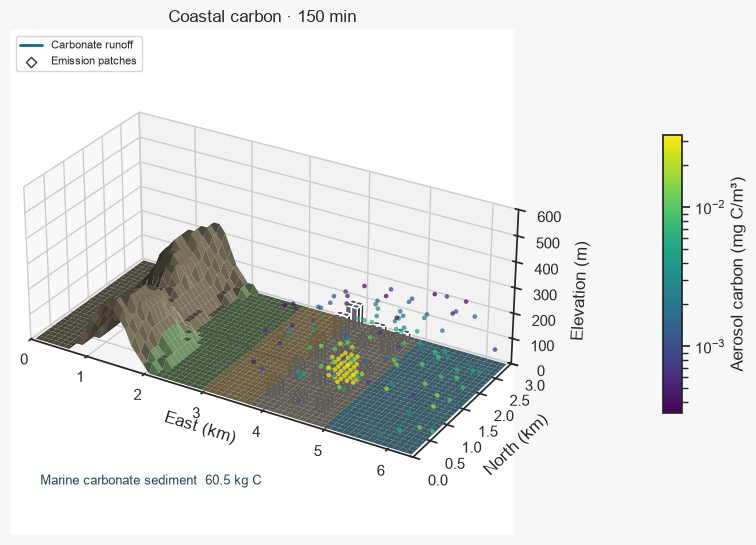

In [12]:
fig = plt.figure(figsize=(9, 5.8), facecolor='#f6f8f8')
fig.subplots_adjust(left=.03, right=.80, bottom=.07, top=.94)
ax = fig.add_subplot(projection='3d')
xx, yy = np.meshgrid(x, y, indexing='ij')
colors = np.array([mpl.colors.to_rgba(color) for color in region_colors])[zones]
ax.plot_surface(xx, yy, ground, facecolors=colors, rstride=1, cstride=1, shade=True, linewidth=0)
i, j = blocks.T
ax.bar3d(i*dx/1000, j*dy/1000, np.zeros(len(i)), dx/1000, dy/1000, land[i,j], color='#736D80', shade=True)
ax.plot(x[river_i], y[river_j], land[river_i,river_j]+7, color='#11658A', lw=2, label='Carbonate runoff')
ax.scatter(x[src_i], y[src_j], z[src_k], color='white', edgecolor='#26343d', marker='D', s=27, label='Emission patches')
ax.set(xlim=(0,6.4), ylim=(0,3), zlim=(0,600), xlabel='East (km)', ylabel='North (km)', zlabel='Elevation (m)')
ax.set_box_aspect((6.4,3,2.5))
ax.view_init(elev=28, azim=-59)
ax.legend(loc='upper left', frameon=True, fontsize=8)
s = 2
norm = LogNorm(vis_min[s], vis_max[s], clip=True)
cax = fig.add_axes([.86, .28, .021, .48])
fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap='viridis'), cax=cax, label='Aerosol carbon (mg C/m³)')
caption = ax.text2D(.06,.10,'',transform=ax.transAxes,fontsize=9,color='#2C4050')
title = ax.set_title('')
artists = {}

def draw_frame(t):
    if 'cloud' in artists:
        artists['cloud'].remove()
    ids, values = cloud(0, t, s)
    i, j, k = np.unravel_index(ids, (nx, ny, nz))
    artists['cloud'] = ax.scatter(x[i], y[j], z[k], c=values, cmap='viridis', norm=norm,
                                  s=11, alpha=.75, edgecolors='none', depthshade=False)
    title.set_text(f'Coastal carbon · {time_s[t]/60:.0f} min')
    caption.set_text(f'Marine carbonate sediment  {stats[0][t][3]:.1f} kg C')
    return artists['cloud'], title, caption


draw_frame(len(time_s)*2//3)
fig.savefig(out / 'coastal_3d.png', dpi=110, facecolor=fig.get_facecolor())
movie = FuncAnimation(fig, draw_frame, frames=len(time_s), interval=250, blit=False)
with mpl.rc_context({'animation.ffmpeg_path': imageio_ffmpeg.get_ffmpeg_exe()}):
    movie.save(out / 'coastal_3d.mp4', dpi=90,
               writer=FFMpegWriter(fps=4, codec='h264', bitrate=420,
                                   extra_args=['-pix_fmt', 'yuv420p', '-movflags', '+faststart']))
display(fig)
plt.close(fig)